# Image segmentation — Gaussian noise

**One transformation per notebook.** This activity loads your own paired  photographs and masks, displays the transformation, and trains a small Keras CNN using the original + transformed **training** examples. Validation photos are untouched.

**Today’s transformation:** Add random sensor-like noise to the photograph only.

## Step 1 — Arrange your folders

Keep this notebook beside `animal_dataset/`:

```text
animal_dataset/
    animals/
        cat_001.jpg
        dog_002.jpg
    masks/
        cat_001.png
        dog_002.png
```

The names before `.jpg` and `.png` must match. No torrent or dataset download is performed.

## Step 2 — Install libraries, if needed

Uncomment the next line only if an import fails.

In [1]:
# %pip install tensorflow pandas numpy pillow matplotlib scikit-learn

## Step 3 — Import our tools

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from sklearn.model_selection import train_test_split
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## Step 4 — Choose where the pictures are stored

Use **Oxford trimap** for the original Oxford-IIIT Pet masks (1 animal, 2 background, 3 boundary), or **binary** for white-foreground masks.

In [3]:
DATA_FOLDER = Path("animal_dataset")
ANIMALS_FOLDER = DATA_FOLDER / "animals"
MASKS_FOLDER = DATA_FOLDER / "masks/trimaps"
MASK_FORMAT = "oxford_trimap"  # Change to "binary" if the masks are black/white
IMAGE_SIZE = (128, 128)
MAX_IMAGES = 10  # Use None to load all matched images
assert ANIMALS_FOLDER.is_dir(), f"Missing folder: {ANIMALS_FOLDER}"
assert MASKS_FOLDER.is_dir(), f"Missing folder: {MASKS_FOLDER}"

## Step 5 — Match animal photographs with their masks

We pair files using the name before the file extension and build the familiar DataFrame with `id`, `image`, `labels`, `mask`.

In [4]:
mask_lookup = {p.stem.lower(): p for p in MASKS_FOLDER.iterdir()
               if p.suffix.lower() in (".png", ".jpg", ".jpeg")}
photos = sorted(p for p in ANIMALS_FOLDER.iterdir()
                if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
pairs = [(p, mask_lookup[p.stem.lower()]) for p in photos
         if p.stem.lower() in mask_lookup]
if MAX_IMAGES is not None:
    pairs = pairs[:MAX_IMAGES]
if len(pairs) < 2:
    raise ValueError("Need at least two matched photos and masks. Check filenames and folders.")
print("Matched pairs:", len(pairs))

Matched pairs: 10


## Step 6 — Load and resize image–mask pairs

Photos are resized smoothly; masks use **nearest neighbour** to preserve their discrete labels. We convert masks into `0 = background`, `1 = animal`.

In [5]:
rows = []
for photo_path, mask_path in pairs:
    photo = Image.open(photo_path).convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    raw_mask = Image.open(mask_path).convert("L").resize(IMAGE_SIZE, Image.Resampling.NEAREST)
    values = np.asarray(raw_mask)
    if MASK_FORMAT == "oxford_trimap":
        binary_mask = (values == 1).astype("uint8")
    elif MASK_FORMAT == "binary":
        binary_mask = (values > 127).astype("uint8")
    else:
        raise ValueError("MASK_FORMAT must be 'oxford_trimap' or 'binary'")
    rows.append({"id": photo_path.stem,
                 "image": np.asarray(photo, dtype="uint8"),
                 "labels": "animal", "mask": binary_mask})
df = pd.DataFrame(rows)
print(df[["id", "labels"]].head())

               id  labels
0    Abyssinian_1  animal
1   Abyssinian_10  animal
2  Abyssinian_100  animal
3  Abyssinian_101  animal
4  Abyssinian_102  animal


## Step 7 — Split into training and validation photos

Split **before** augmentation. This prevents a flipped or rotated copy of a training photo from appearing in validation.

In [6]:
train_df, val_df = train_test_split(df, test_size=0.2, random_state=SEED, shuffle=True)
print("Training:", len(train_df), "Validation:", len(val_df))

Training: 8 Validation: 2


## Step 8 — Apply one transformation: Gaussian noise

Add random sensor-like noise to the photograph only.

**Remember:** geometric changes (flip, rotation, zoom, translation) affect both the image and mask. Changes to colour or noise affect only the photograph.

In [7]:
def add_noise(image, seed):
    rng = np.random.default_rng(seed)
    pixels = np.asarray(image, dtype=np.float32)
    noisy = np.clip(pixels + rng.normal(0, 12, pixels.shape), 0, 255)
    return Image.fromarray(noisy.astype("uint8"), mode="RGB")

def transform_pair(image_array, mask_array, sample_number=0):
    # Convert arrays to simple PIL pictures.
    image = Image.fromarray(image_array)
    mask = Image.fromarray(mask_array)

    # This notebook uses exactly ONE augmentation.
    new_image, new_mask = add_noise(image, seed=SEED + sample_number), mask.copy()

    return np.asarray(new_image, dtype="uint8"), np.asarray(new_mask, dtype="uint8")

## Step 9 — Look at the original and transformed versions

Notice that the white animal pixels stay aligned with the animal after geometric transformations.

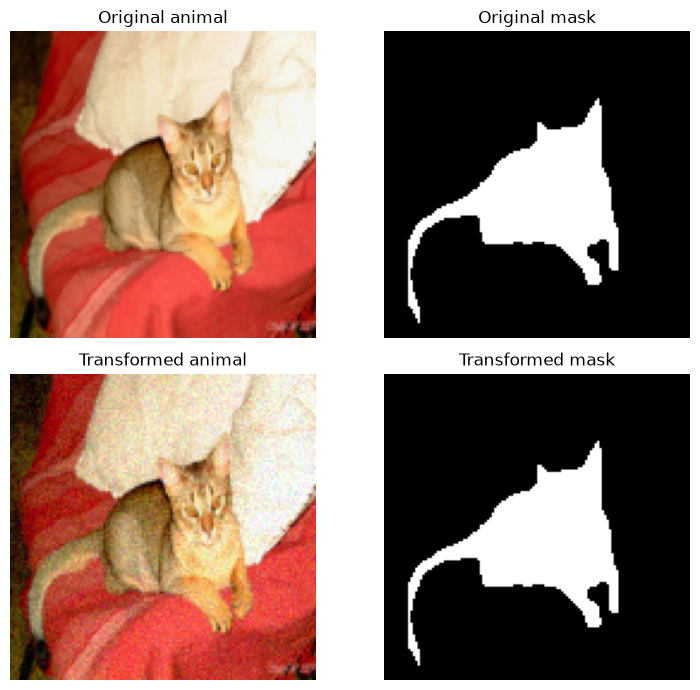

In [8]:
sample = train_df.iloc[0]
new_photo, new_mask = transform_pair(sample["image"], sample["mask"])
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
axes[0, 0].imshow(sample["image"])
axes[0, 0].set_title("Original animal")
axes[0, 1].imshow(sample["mask"], cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Original mask")
axes[1, 0].imshow(new_photo)
axes[1, 0].set_title("Transformed animal")
axes[1, 1].imshow(new_mask, cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Transformed mask")
for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()
plt.show()

## Step 10 — Make a larger training set

We keep each original training example and add **one transformed copy**. This doubles the number of training samples. We leave validation unchanged.

In [9]:
X_original = np.stack(train_df["image"].to_numpy())
y_original = np.stack(train_df["mask"].to_numpy())
transformed = [transform_pair(row["image"], row["mask"], sample_number=i)
               for i, (_, row) in enumerate(train_df.iterrows())]
X_extra = np.stack([item[0] for item in transformed])
y_extra = np.stack([item[1] for item in transformed])
X_train = np.concatenate([X_original, X_extra]).astype("float32") / 255.0
y_train = np.concatenate([y_original, y_extra]).astype("float32")[..., None]
X_val = np.stack(val_df["image"].to_numpy()).astype("float32") / 255.0
y_val = np.stack(val_df["mask"].to_numpy()).astype("float32")[..., None]
print("Original training photos:", len(X_original))
print("Training examples after augmentation:", len(X_train))
print("Untouched validation photos:", len(X_val))

Original training photos: 8
Training examples after augmentation: 16
Untouched validation photos: 2


## Step 11 — Build a small segmentation CNN with Keras

The CNN outputs one probability per pixel. This is a simple encoder–decoder suitable for learning, not a state-of-the-art model.

In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.UpSampling2D(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.UpSampling2D(),
    tf.keras.layers.Conv2D(1, 1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 1)    │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,081 (164.38 KB)

 Trainable params: 42,081 (164.38 KB)

 Non-trainable params: 0 (0.00 B)

## Step 12 — Train the model

Start with three epochs, then try five or ten if your computer is fast enough.

In [11]:
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=3, batch_size=16)

Epoch 1/3
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 762ms/step - binary_accuracy: 0.4135 - loss: 0.6956 - val_binary_accuracy: 0.7961 - val_loss: 0.6786
Epoch 2/3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - binary_accuracy: 0.7671 - loss: 0.6741 - val_binary_accuracy: 0.7964 - val_loss: 0.6601
Epoch 3/3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - binary_accuracy: 0.7679 - loss: 0.6535 - val_binary_accuracy: 0.7964 - val_loss: 0.6392


## Step 13 — Predict the mask of one validation photograph

The model predicts a probability from 0 to 1 at every pixel. Values above 0.5 become animal pixels.

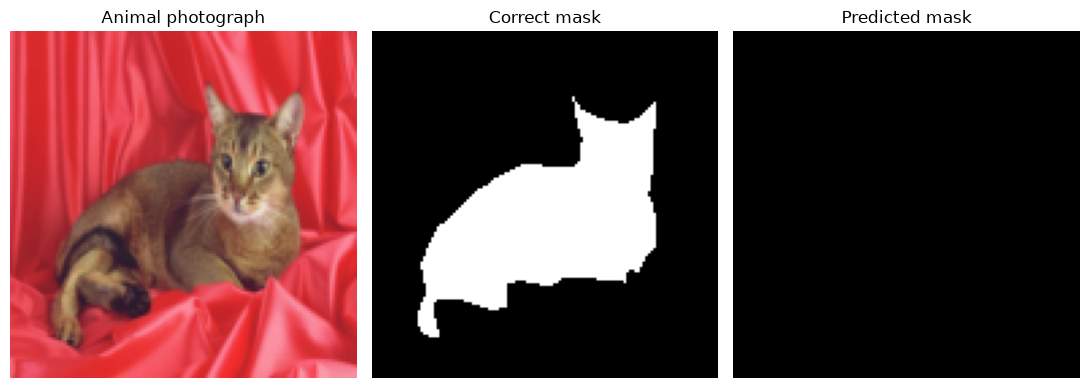

In [12]:
example = val_df.iloc[0]
photo = np.asarray(example["image"], dtype="float32") / 255.0
prediction = model.predict(photo[None, ...], verbose=0)[0, :, :, 0]
predicted_mask = (prediction > 0.5).astype("uint8")
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(example["image"]); axes[0].set_title("Animal photograph")
axes[1].imshow(example["mask"], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Correct mask")
axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1); axes[2].set_title("Predicted mask")
for axis in axes: axis.axis("off")
plt.tight_layout()
plt.show()

## Step 14 — Measure overlap with IoU

**Intersection over Union** measures how much the predicted animal region overlaps the true region. Larger is better (maximum 1).

In [13]:
truth = example["mask"].astype(bool)
pred = predicted_mask.astype(bool)
intersection = np.logical_and(truth, pred).sum()
union = np.logical_or(truth, pred).sum()
iou = intersection / union if union else 1.0
print("IoU for this image:", round(float(iou), 3))

IoU for this image: 0.0


## Step 15 — Student experiments

1. Change the first sample in Step 9. Does the transformation still look realistic?
2. Train for more epochs. Does the result improve?
3. Compare this notebook against a **no-augmentation baseline**, using the same train/validation split, architecture, and epochs.
4. Explain why the validation set must never contain augmented versions of training photographs.

**Takeaway:** Add random sensor-like noise to the photograph only.